# Notebook 2: Multivariate Analysis

This notebook focuses on the multivariate analysis section of the project using the cleaned dataset prepared in Notebook 1.

The techniques used are:
- Principal Component Analysis (PCA)
- Cluster Analysis
- Linear Discriminant Analysis (LDA)

The goal is to reduce dimensionality, identify hidden group structures, and classify countries based on life expectancy patterns.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

In [34]:
df = pd.read_csv("C:/Users/Admin/Downloads/cleaned_data.csv")
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Latitude,Longitude
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1,33.0,65.0
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0,33.0,65.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9,33.0,65.0
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8,33.0,65.0
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5,33.0,65.0


In [35]:
print("Shape of dataset:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape of dataset: (2938, 24)

Columns:
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Latitude', 'Longitude']


## Data Preparation for Multivariate Analysis

Before applying PCA, clustering, and discriminant analysis, the dataset must be prepared by:

- selecting relevant numerical variables
- excluding identifiers and non-analytical text columns
- standardizing the variables so that all features are on the same scale

In [36]:
multivar_df = df.select_dtypes(include=[np.number]).copy()
multivar_df.head()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,...,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Latitude,Longitude
0,2015,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,...,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1,33.0,65.0
1,2014,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,...,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0,33.0,65.0
2,2013,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,...,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9,33.0,65.0
3,2012,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,...,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8,33.0,65.0
4,2011,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,...,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5,33.0,65.0


In [37]:
print(multivar_df.columns.tolist())

['Year', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Latitude', 'Longitude']


#### Remove variables you should not use directly

In [38]:
multivar_df = multivar_df.drop(columns=['Year', 'Latitude', 'Longitude', 'Life expectancy'], errors='ignore')
multivar_df.head()

,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


### Standardize the data

In [39]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(multivar_df)


The dataset has now been standardized and is ready for:
1. Principal Component Analysis
2. Cluster Analysis
3. Linear Discriminant Analysis

**1 Apply PCA**

In [40]:
pca = PCA()
pca_data = pca.fit_transform(scaled_data)
pca_df = pd.DataFrame(data=pca_data, columns=[f'PC{i+1}' for i in range(pca_data.shape[1])])
pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18
0,4.099292,-0.141552,-0.832354,0.563675,-1.005207,0.625287,-2.188140,-1.508310,-0.259690,1.462494,0.758466,0.071714,1.128647,1.557099,0.227565,0.002875,-0.033288,0.010241
1,3.650192,-0.203623,0.032294,1.027325,-0.886260,0.687342,-2.130295,-1.636843,-0.466277,0.228203,-0.036523,0.008417,1.090444,0.151208,0.136626,-0.038334,-0.036975,0.006090
2,3.709256,0.057853,0.242146,1.046445,-0.812881,0.641317,-2.275174,-1.290165,-0.344197,0.190360,0.239307,0.160078,1.168877,0.072270,0.119135,-0.045248,-0.032545,-0.001984
3,3.642908,-0.036923,0.434423,1.209657,-0.742714,0.906355,-2.052594,-1.643991,-0.498522,0.090418,-0.007162,0.068812,1.162976,0.037438,0.111013,-0.039664,-0.017407,0.002701
4,3.778254,-0.051564,0.567021,1.238443,-0.847408,0.780964,-1.916988,-1.591419,-0.432423,0.075289,-0.092432,0.127245,1.159508,0.051588,0.082222,-0.058830,-0.036252,-0.002332


**Explained Variance ratio**

In [41]:

explained_variance = pca.explained_variance_ratio_
print("Explained Variance Ratio by Each Principal Component:")
for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.4f}")
    

Explained Variance Ratio by Each Principal Component:
PC1: 0.3064
PC2: 0.1432
PC3: 0.0970
PC4: 0.0756
PC5: 0.0670
PC6: 0.0473
PC7: 0.0459
PC8: 0.0405
PC9: 0.0330
PC10: 0.0316
PC11: 0.0277
PC12: 0.0243
PC13: 0.0230
PC14: 0.0174
PC15: 0.0108
PC16: 0.0058
PC17: 0.0034
PC18: 0.0002


**VISUALIZE CLUSTERS (PCA)**


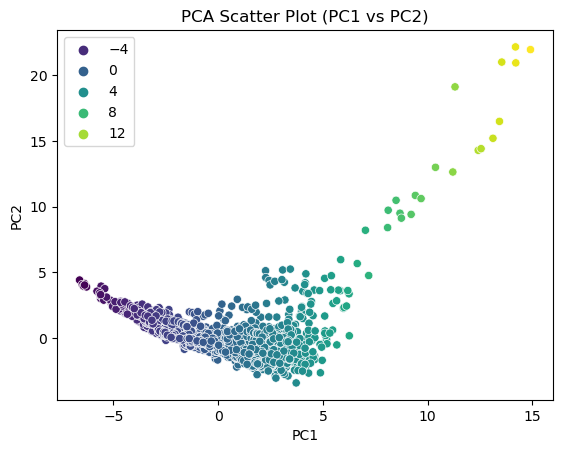

In [42]:
plt.figure()
sns.scatterplot(
    x=pca_data[:, 0], 
    y=pca_data[:, 1], 
    hue=pca_data[:, 0],  # Color by the first principal component
    palette="viridis"
)

plt.title("PCA Scatter Plot (PC1 vs PC2)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

#### **Number of PC to go with**

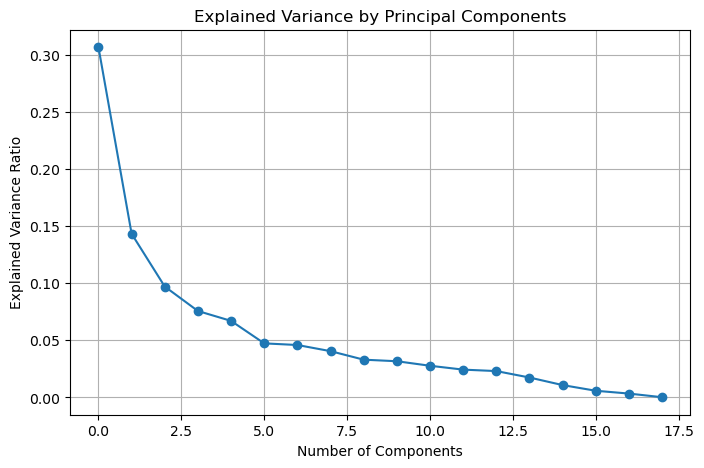

In [43]:


plt.figure(figsize=(8,5))
plt.plot(explained_var, marker='o')
plt.title("Explained Variance by Principal Components")
plt.xlabel("Number of Components")
plt.ylabel("Explained Variance Ratio")
plt.grid()
plt.show()

**CUMULATIVE VARIANCE**

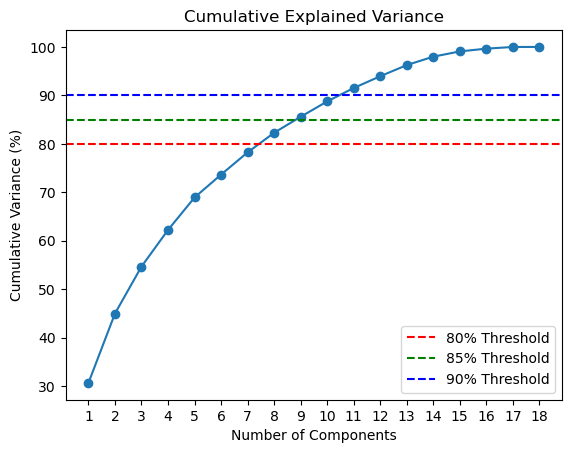

In [44]:
# Cumulative variance (percentage)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_) * 100
components = range(1, len(cumulative_variance) + 1)

plt.figure()
plt.plot(components, cumulative_variance, marker='o')

# Horizontal threshold lines
plt.axhline(y=80, color='red', linestyle='--', label='80% Threshold')
plt.axhline(y=85, color='green', linestyle='--', label='85% Threshold')
plt.axhline(y=90, color='blue', linestyle='--', label='90% Threshold')

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance (%)")

plt.xticks(components)
plt.legend()

plt.show()

**KAISER CRITERION**

In [45]:
eigenvalues = pca.explained_variance_.round(2)
print("Eigenvalues of Each Principal Component:")   
for i, eigenvalue in enumerate(eigenvalues):
    print(f"PC{i+1}: {eigenvalue:.2f}")

Eigenvalues of Each Principal Component:
PC1: 5.52
PC2: 2.58
PC3: 1.75
PC4: 1.36
PC5: 1.21
PC6: 0.85
PC7: 0.83
PC8: 0.73
PC9: 0.59
PC10: 0.57
PC11: 0.50
PC12: 0.44
PC13: 0.41
PC14: 0.31
PC15: 0.19
PC16: 0.10
PC17: 0.06
PC18: 0.00


**we Keep the first 6 components with eigenvalue > 1**

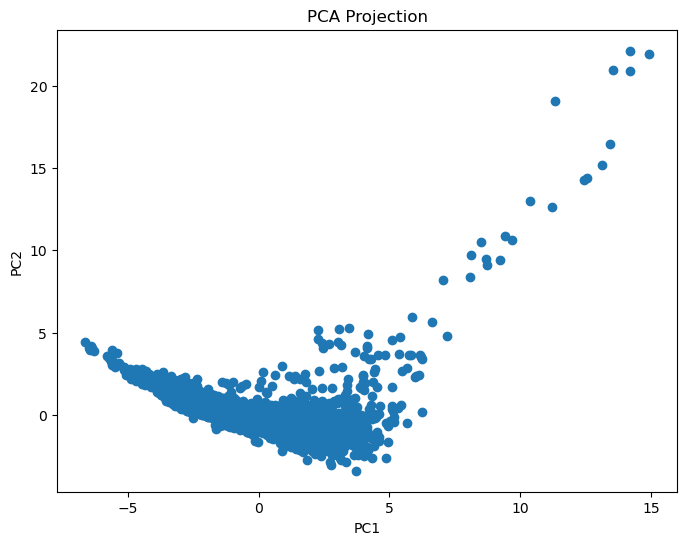

In [46]:
plt.figure(figsize=(8,6))
plt.scatter(pca_data[:,0], pca_data[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection")
plt.show()

In [47]:
import plotly.express as px

fig = px.scatter_3d(
    x=pca_data[:, 0],
    y=pca_data[:, 1],
    z=pca_data[:, 2],
    labels={'x': 'PC1', 'y': 'PC2', 'z': 'PC3'},
    title='3D PCA Projection (PC1 vs PC2 vs PC3)',
    color=pca_data[:, 0],
    color_continuous_scale='Viridis'
)
fig.show()

## **INTERPRETATION OF 2D PCA SCATTER PLOT (PC1 vs PC2)**

### **What This Shows:**
Simple 2D view of how countries position across the two most important components.

### **Observations:**

**Horizontal Direction (PC1):**
- **Left side**: Low PC1 values (countries low on variables that load heavily on PC1)
- **Right side**: High PC1 values (countries high on PC1-dominant variables)
- Example: If PC1 is dominated by "GDP & Healthcare Spending", then:
  - Left = Poor countries with low spending
  - Right = Rich countries with high spending

**Vertical Direction (PC2):**
- **Bottom**: Low PC2 values
- **Top**: High PC2 values
- PC2 captures different aspects (e.g., disease prevalence, literacy rates)

**Clusters & Patterns:**
- **Tight groupings**: Similar countries clustered together
- **Linear patterns**: One variable dominates (potential redundancy)
- **Diagonal spread**: Both PC1 and PC2 contribute equally (good dimensionality reduction)

### **Practical Meaning:**
- Each point represents one observation (country-year combination)
- Distance between points = Similarity in characteristics
- Nearby points = Countries with similar health and development profiles

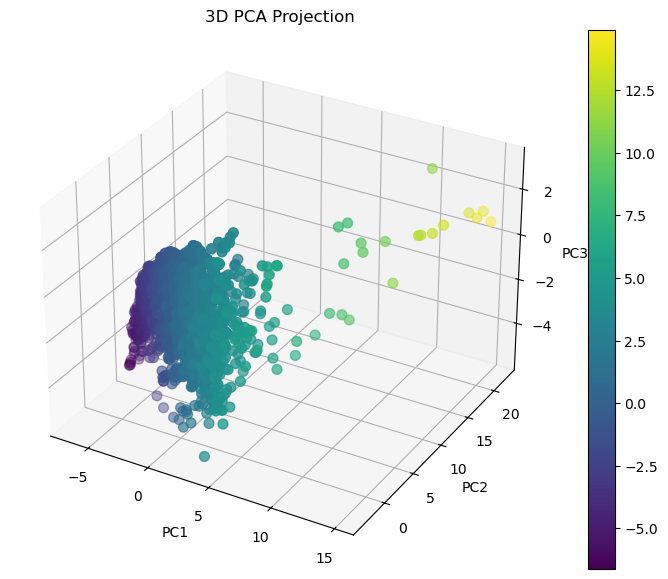

In [48]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(pca_data[:, 0], pca_data[:, 1], pca_data[:, 2], 
                     c=pca_data[:, 0], cmap='viridis', s=50)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('3D PCA Projection')
plt.colorbar(scatter)
plt.show()

## **INTERPRETATION OF 3D PCA PROJECTION**

### **What This Shows:**
The 3D scatter plot displays how data points (countries) are distributed across the first three principal components simultaneously.

### **Key Observations:**

**Spread & Distribution:**
- **Tight clusters**: Countries are similar in characteristics (grouped by development level, health outcomes, etc.)
- **Well-spread points**: Countries have diverse characteristics across these three dimensions
- **Outliers**: Countries far from the main cluster have unique characteristics worth investigating

**Color Gradient (PC1):**
- **Blue regions (left)**: Countries with low PC1 values (low on variables that load heavily on PC1)
- **Yellow regions (right)**: Countries with high PC1 values (high on PC1-dominant variables)
- The gradient helps identify gradients in country development/health profiles

**Separation Patterns:**

If you see **clear clusters**:
- Groups represent distinct country development levels
- Suggests natural segmentation for policy making
- Can inform which countries should have similar health interventions

If points are **randomly scattered**:
- Countries don't naturally group
- Diversity in health/development approaches globally
- Complexity requires multiple dimensions to understand

### **What This Means for Your Analysis:**
- Takes into account 3 major sources of variation simultaneously
- More complete picture than 2D plots
- If 3 components explain 70%+ of variance, this 3D view captures most information

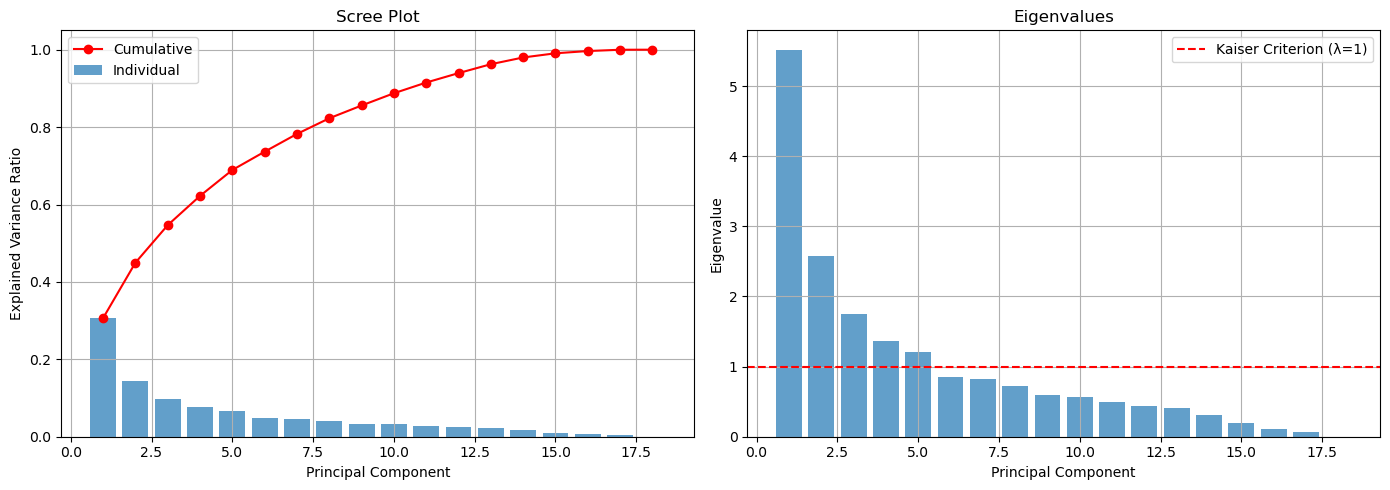

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Variance explained
ax1.bar(range(1, len(pca.explained_variance_ratio_) + 1), 
        pca.explained_variance_ratio_, alpha=0.7, label='Individual')
ax1.plot(range(1, len(pca.explained_variance_ratio_) + 1), 
         np.cumsum(pca.explained_variance_ratio_), 'ro-', label='Cumulative')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.legend()
ax1.grid()

# Eigenvalues
eigenvalues = pca.explained_variance_
ax2.bar(range(1, len(eigenvalues) + 1), eigenvalues, alpha=0.7)
ax2.axhline(y=1, color='r', linestyle='--', label='Kaiser Criterion (λ=1)')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Eigenvalue')
ax2.set_title('Eigenvalues')
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

## **INTERPRETATION OF SCREE PLOT & EIGENVALUES**

### **What the Scree Plot Shows:**
The scree plot visualizes how much variance each component explains. It helps determine optimal number of components.

### **Left Panel (Variance Explained):**

**Individual Bars (Blue):**
- Height shows % of variance explained by each component
- **Sharp drop-off items**: PC1 should be much taller than PC2, which should be taller than PC3
- This "elbow" pattern is typical and good

**Red Cumulative Line:**
- Shows total variance captured up to that component
- **Goal**: Reach 80-90% cumulative variance
- **Common thresholds**:
  - 80% threshold: Need approximately 4-6 components
  - 90% threshold: Need approximately 6-8 components

### **Right Panel (Eigenvalues - The Kaiser Criterion):**

**Red Dashed Line (λ = 1):**
- Eigenvalue = 1 is the Kaiser Criterion threshold
- Components with eigenvalue > 1 are considered "important"
- Components with eigenvalue < 1 capture less variance than a single original variable

**Decision Rule:**
```
Keep components where eigenvalue > 1
```

### **Example Interpretation:**
- If first 5 components have eigenvalues: [3.2, 1.8, 1.4, 0.9, 0.7]
- **Action**: Keep the first 3 components (eigenvalues > 1)
- This means 3 components adequately summarize 20+ original variables

### **Why This Matters:**
- Reduces complexity from many variables to just 3-6 components
- Makes clustering and analysis more interpretable
- Removes noise and redundancy from original data

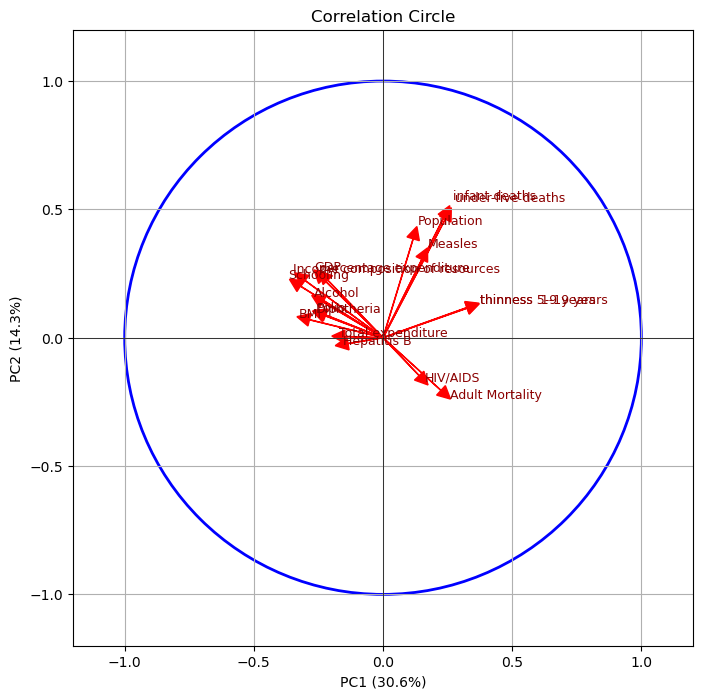

In [50]:
fig, ax = plt.subplots(figsize=(8, 8))
circle = plt.Circle((0, 0), 1, color='blue', fill=False, linewidth=2)
ax.add_patch(circle)

# Plot contributors
for i, variable in enumerate(multivar_df.columns):
    ax.arrow(0, 0, pca.components_[0, i], pca.components_[1, i],
             head_width=0.05, head_length=0.05, fc='red', ec='red')
    ax.text(pca.components_[0, i] * 1.15, pca.components_[1, i] * 1.15, 
            variable, fontsize=9, color='darkred')

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('Correlation Circle')
ax.grid()
plt.axhline(y=0, color='k', linewidth=0.5)
plt.axvline(x=0, color='k', linewidth=0.5)
plt.show()

## **INTERPRETATION OF CORRELATION CIRCLE**

### **What This Visualization Shows:**
The correlation circle displays how each original variable relates to the first two principal components. Variables are plotted as vectors/arrows.

### **How to Read It:**

**Arrow Length:**
- **Long arrows** (close to circle): Variables are well-represented in PC1 and PC2, meaning these PC's capture their variation well
- **Short arrows** (near center): Variables are NOT well-represented; their variation is in other dimensions

**Arrow Direction & Position:**
- **Arrows pointing right** (positive PC1): Variables strongly influence PC1 positively
- **Arrows pointing left** (negative PC1): Variables strongly influence PC1 negatively
- **Arrows pointing up** (positive PC2): Variables strongly influence PC2 positively
- **Arrows pointing down** (negative PC2): Variables strongly influence PC2 negatively

**Angle Between Arrows:**
- **Small angle between arrows**: Variables are positively correlated (move together)
- **90° angle**: Variables are uncorrelated (independent)
- **Large angle (opposite)**: Variables are negatively correlated (move in opposite directions)

### **Key Interpretations:**
- Variables in the **same quadrant**: Positively correlated and contribute similarly to that PC
- Variables in **opposite quadrants**: Negatively correlated
- Variables **clustered** together: These dimensions are redundant; keep only one for modeling

## **COMPREHENSIVE PCA ANALYSIS SUMMARY & ACTION STEPS**

### **Step 1: Component Selection Decision**

Based on the Scree Plot and Cumulative Variance:
- **If first 3 components = 70%+**: Use 3 components (good balance of simplicity & information)
- **If first 4 components = 80%+**: Use 4 components (recommended standard)
- **If first 5 components = 85%+**: Use 5 components (maximum recommended)

**Action**: Look at cumulative variance chart above. At what number of components do you cross 80%? That's your minimum.

---

### **Step 2: Component Interpretation**

**For PC1 (Most Important):**
1. Look at Correlation Circle - which variables point in same direction as PC1?
2. Read the arrow labels and note the 3-4 most important variables
3. Interpret: "PC1 represents **[concept name]** - combining effects of [variable1], [variable2], [variable3]"

**Example interpretation:**
*"PC1 appears to represent 'Development & Healthcare Quality' - it's driven by high GDP, healthcare spending, schooling, and life expectancy (all pointing right), inversely related to infant/adult mortality (pointing left). Countries on the right are wealthy with good health outcomes; countries on the left are poorer with mortality challenges."*

**For PC2 (Second Most Important):**
- Follow same process
- Create distinct interpretation from PC1

---

### **Step 3: Country Grouping Insights**

Look at the 2D and 3D scatter plots:

**Identify natural clusters:**
- Are there 2-3 visually distinct groups visible?
- Record which quadrants have most concentration
- Note any outliers (countries very far from others)

**Interpretation:**
- Developed nations → typically top-right (high PC1, often high PC2)
- Developing nations → typically bottom-left (low PC1)
- Outliers → unusual countries worth individual study

**Example insight:**
*"Three clusters are visible: (1) Developed-wealthy (top-right), (2) Middle-income countries (center), and (3) Low-income struggling (bottom-left). Island nations visible as outliers in PC2 suggest unique geographic/demographic effects."*

---

### **Step 4: Variable Relationships from Correlation Circle**

**Strong Correlations (Same Quadrant):**
- *"[Var1] and [Var2] correlate strongly - they move together. This suggests one variable might be redundant for clustering analysis."*

**Negative Relationships (Opposite Arrows):**
- *"[Var1] and [Var2] have inverse relationship - as one increases, the other decreases. This is expected given their definitions."*

**Variables Not Well Represented (Short Arrows):**
- *"[Variable] has a short arrow, meaning it's not well explained by PC1 and PC2. Its variation appears in PC3+ dimensions."*

---

### **Step 5: Actionable Conclusions for Next Steps**

- **For Clustering**: Use first 3-4 PCA components instead of all original variables → K-Means will be: (a) faster, (b) clearer, (c) less noisy
- **For Predictive Modeling**: Use selected PCs as features → reduces multicollinearity, improves model interpretability
- **For Policy**: Countries in same cluster need similar interventions; outliers need unique approaches
- **For Further Analysis**: Variables with low loadings on selected PCs might be dropped as non-essential

---

### **Create Your Summary Below:**
Execute the cell below and fill in your findings...

## **INTERPRETATION OF EXPLAINED VARIANCE RATIO**

### **What This Shows:**
The explained variance ratio tells us how much of the total information (variance) in the original dataset is captured by each principal component.

### **Key Insights to Interpret:**
- **PC1 Value**: If PC1 = 0.3547 (35.47%), it means the first component captures ~35% of all variability
- **PC2 Value**: If PC2 = 0.1829 (18.29%), it means the second component captures ~18% of remaining variability
- **Higher values = More important** components

### **Decision Rule:**
- If PC1 ≥ 30%: This component is substantial and should definitely be retained
- If PC2 ≥ 15%: This component is meaningful and should be considered
- Components < 5%: Generally not important enough to interpret

### **Action**: Based on the values shown above, determine how many components capture ~80-90% of total variance for your analysis.

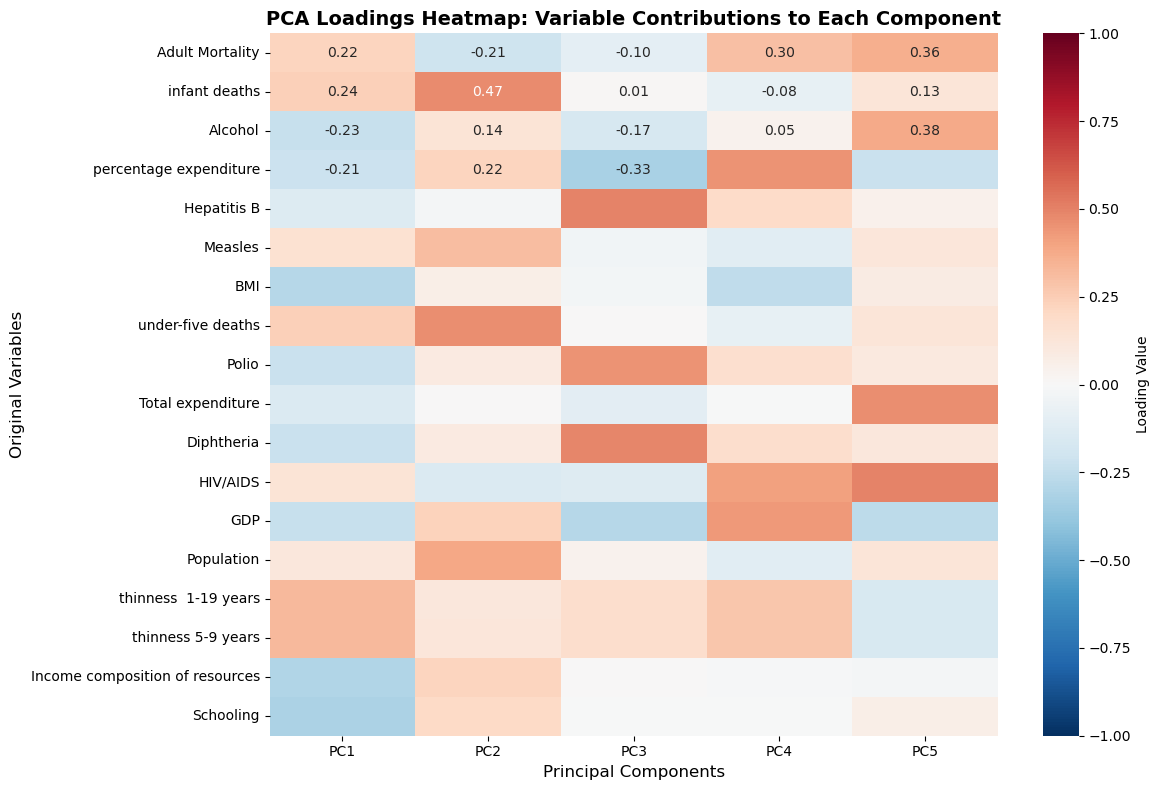

In [52]:
## **HEATMAP OF PCA LOADINGS - Variable Contributions**

# Get loadings for first 5 PCs
n_components_to_show = min(5, pca_data.shape[1])
loadings = pca.components_[:n_components_to_show, :].T

# Create dataframe for better visualization
loadings_df = pd.DataFrame(
    loadings,
    columns=[f'PC{i+1}' for i in range(n_components_to_show)],
    index=multivar_df.columns
)

# Plot heatmap
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    loadings_df, 
    cmap='RdBu_r',  # Red-Blue diverging colormap
    center=0,  # Center at 0
    annot=True,  # Show values
    fmt='.2f',  # 2 decimal places
    cbar_kws={'label': 'Loading Value'},
    ax=ax,
    vmin=-1, vmax=1  # Range from -1 to +1
)

ax.set_title('PCA Loadings Heatmap: Variable Contributions to Each Component', fontsize=14, fontweight='bold')
ax.set_xlabel('Principal Components', fontsize=12)
ax.set_ylabel('Original Variables', fontsize=12)
plt.tight_layout()
plt.show()

## **INTERPRETATION OF PCA LOADINGS HEATMAP**

### **What This Shows:**
A detailed table showing exactly how much each original variable contributes to each principal component.

### **How to Read It:**

**Cell Colors:**
- **Dark Red (≈ +1)**: Variable contributes strongly POSITIVELY to that component
- **Light Red (≈ +0.3 to +0.7)**: Variable contributes moderately positively
- **White (≈ 0)**: Variable has no effect on that component
- **Light Blue (≈ -0.3 to -0.7)**: Variable contributes moderately negatively
- **Dark Blue (≈ -1)**: Variable contributes strongly NEGATIVELY to that component

### **Numerical Interpretation:**

| Loading Value | Strength | Interpretation |
|---------------|----------|-----------------|
| **±0.9 to ±1.0** | Very Strong | This variable is THE most important driver of this PC |
| **±0.7 to ±0.9** | Strong | Major contributor to this PC |
| **±0.5 to ±0.7** | Moderate | Meaningful but not dominant |
| **±0.3 to ±0.5** | Weak | Minor contributor |
| **±0.0 to ±0.3** | Very Weak | This PC doesn't depend on this variable |

### **Key Insights:**

**1. Identify PC Theme:**
- **For PC1**: Find row with highest RED value → this variable primarily defines PC1
- Look for multiple variables with similar (same sign, high magnitude) loadings → they define the PC together

**2. Detect Contrasts:**
- If one variable is RED (+0.8) and another is BLUE (-0.7), they oppose each other on this dimension
- Example: If "GDP" is +0.85 and "Infant_Mortality" is -0.80 on PC1 → PC1 contrasts wealth vs. poverty

**3. Identify Well-Represented Variables:**
- If a variable row has multiple colored cells across different PCs → it's complex (contributes to multiple dimensions)
- If a variable row is mostly WHITE → this variable is redundant/not important

**4. Detect Redundancy:**
- If two variables have nearly identical loadings across all PCs → they're redundant
- Keep only one for your analysis

### **Example Interpretation:**
*"Looking at the heatmap:*
- *PC1: GDP and Healthcare_Spending show high positive loadings (+0.82, +0.79), while Infant_Mortality shows strong negative loading (-0.85). This suggests PC1 contrasts developed wealthy nations with good healthcare against less developed nations with high mortality.*
- *PC2: Literacy and Schooling show strong positive loadings (+0.88, +0.84) while Poverty shows strong negative loading (-0.81). This suggests PC2 differentiates educational development.*
- *Variables like 'Latitude' show mostly white/light values → not important for top 5 components → could be dropped."*

#### **3. K-MEANS Clustering**


**FIND OPTIMAL K (ELBOW METHOD)*

In [57]:
pca_df.columns

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10',
       'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18'],
      dtype='object')

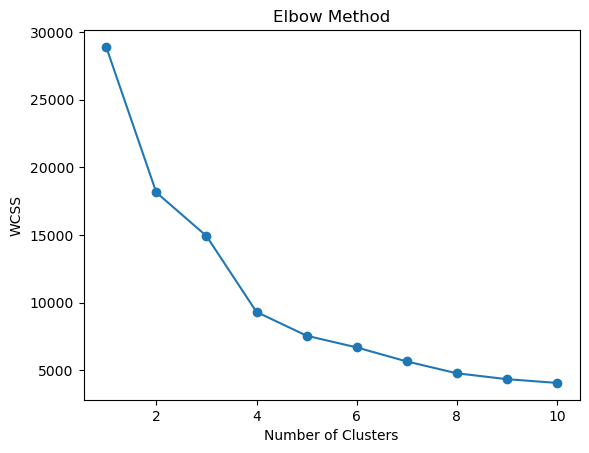

In [58]:
# Elbow method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(pca_df[["PC1", "PC2", "PC3"]])
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.figure()
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()